# Combining Vector Search, SQL, JSON, and Metadata for AI Memory

A practical Oracle AI Database workflow for storing durable memory, applying structured governance, and retrieving the right context.

This workflow keeps the responsibilities visible: SQL columns carry operational constraints, JSON carries flexible metadata, and vector search finds semantically related records. The same retrieval request can use all three without moving the data through separate stores.

## What This Notebook Demonstrates

By the end, you will have a runnable Oracle AI Database-backed memory table that demonstrates:

1. A secure connection profile that works with Autonomous AI Database in the cloud or Oracle Database Free in Docker.
2. Database-resident ONNX embeddings generated with `VECTOR_EMBEDDING`.
3. A memory schema that combines typed SQL columns, a native JSON metadata column, validity fields, and a `VECTOR` column.
4. The Oracle AI Agent Memory SDK for explicit memory writes, scoped metadata filtering, updates, and deletion.
5. A transparent SQL/JSON/vector database layer that shows the same governance ideas without hiding the database contract.
6. Evaluation checks for relevance, scope isolation, freshness, and exact-match behavior.

The sample uses synthetic support records. It does not claim that a vector score proves authority, freshness, or authorization; those properties are enforced by the SQL predicates and application policy around the search.

## The Data Model

| Layer | Example in this notebook | Responsibility |
| --- | --- | --- |
| Relational SQL | `owner_id`, `memory_type`, `status`, `source_version`, `valid_until` | Scope, lifecycle, joins, and operational predicates |
| JSON metadata | `tenant`, `domain`, `authority`, `source_type`, `tags` | Flexible attributes that travel with the memory |
| Vector | `embedding` | Semantic similarity for natural-language recall |
| Content | `content` | The evidence or memory text returned to the application |

These are design roles, not separate storage requirements. The same Oracle AI Database table can hold them, while the application still decides which records are eligible to reach the model.

## Connection Options

The notebook reads credentials only from `.env` or the process environment. It never prints the username, password, DSN, wallet path, or model name.

**Autonomous AI Database in Oracle Cloud**

For a free-tier development option, see [Oracle Cloud Free Tier](https://www.oracle.com/cloud/free/). When using an Autonomous AI Database service, set `ORACLE_DSN` to the service alias or Easy Connect Plus value used by your wallet configuration. Keep the wallet location and credentials outside the notebook.

**Oracle AI Database Free locally**

Run [Oracle AI Database locally with Docker or Podman](https://docs.oracle.com/en/database/oracle/agent-memory/26.8/guide/run-locally.html). Set `ORACLE_DSN` to a reachable service such as `localhost:1521/FREEPDB1`. The database must contain an ONNX text-embedding model visible to the schema. This notebook does not create it: load it first in the same schema with the steps in `onnx_embeddings_oracle_ai_database.ipynb` (same folder), which registers the all-MiniLM-L12-v2 model as `ALL_MINILM_L12_V2` with 384 dimensions. Then set `ORACLE_DB_EMBEDDING_MODEL=ALL_MINILM_L12_V2` and `ORACLE_DB_EMBEDDING_DIMENSION=384`.

Both routes use the same Python `oracledb` connection code. Only the environment-specific connection profile changes.


## Prerequisites

- Python 3.11 or later in the project virtual environment.
- `oracledb`, `pandas`, `python-dotenv`, `matplotlib`, `nbformat`, `nbclient`, and `oracleagentmemory` installed from the project requirements.
- Oracle AI Database with the `VECTOR` type and a database-resident ONNX embedding model.
- A schema permitted to create and query its own demo table and indexes.

Required settings:

```text
ORACLE_USER=...
ORACLE_PASSWORD=...
ORACLE_DSN=...
ORACLE_DB_EMBEDDING_MODEL=...
ORACLE_DB_EMBEDDING_DIMENSION=...
```

The dimension must match the model registered in the database. The notebook validates that before creating the table.

In [1]:
import json
import os
import re
import uuid
from datetime import datetime, timezone
from pathlib import Path

import oracledb
import pandas as pd
from dotenv import load_dotenv
from IPython.display import display

print("Python runtime and notebook dependencies: READY")

Python runtime and notebook dependencies: READY


## Step 1 - Load Configuration Without Exposing Secrets

In [2]:
def find_project_dir(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / ".env").exists():
            return candidate
    raise FileNotFoundError(
        "No .env file was found in the current directory or its parents."
    )


PROJECT_DIR = find_project_dir(Path.cwd())
load_dotenv(PROJECT_DIR / ".env", override=False)

required_settings = [
    "ORACLE_USER",
    "ORACLE_PASSWORD",
    "ORACLE_DSN",
    "ORACLE_DB_EMBEDDING_MODEL",
    "ORACLE_DB_EMBEDDING_DIMENSION",
]
missing_settings = [name for name in required_settings if not os.getenv(name, "").strip()]
if missing_settings:
    raise RuntimeError(
        "Missing required settings: " + ", ".join(missing_settings)
    )

EMBEDDING_DIMENSION = int(os.environ["ORACLE_DB_EMBEDDING_DIMENSION"])
if EMBEDDING_DIMENSION <= 0:
    raise ValueError("ORACLE_DB_EMBEDDING_DIMENSION must be greater than zero.")

# Model names are SQL identifiers, not values. Validate before interpolating
# the identifier into the VECTOR_EMBEDDING expression.
MODEL_NAME = os.environ["ORACLE_DB_EMBEDDING_MODEL"].strip()
if not re.fullmatch(
    r"[A-Za-z][A-Za-z0-9_$#]*(?:\.[A-Za-z][A-Za-z0-9_$#]*)*",
    MODEL_NAME,
):
    raise ValueError("ORACLE_DB_EMBEDDING_MODEL is not a safe SQL identifier.")


## Step 2 - Connect to Oracle AI Database

In [3]:
connection = None
DB_READY = False
DB_BLOCKER = ""

try:
    connection = oracledb.connect(
        user=os.environ["ORACLE_USER"],
        password=os.environ["ORACLE_PASSWORD"],
        dsn=os.environ["ORACLE_DSN"],
    )
    DB_READY = True
    print("Oracle AI Database connection: READY")
except oracledb.Error as exc:
    error = exc.args[0] if exc.args else None
    DB_BLOCKER = (
        "Oracle AI Database is not reachable with the current settings. "
        "Start the Docker database or update the Autonomous AI Database profile."
    )
    print("Oracle AI Database connection: BLOCKED")
    print(f"Oracle driver error code: {getattr(error, 'code', 'unknown')}")
    print(DB_BLOCKER)


def require_database_ready() -> None:
    if not DB_READY:
        raise RuntimeError(DB_BLOCKER)

Oracle AI Database connection: READY


## Step 3 - Validate the Database Embedding Model

`VECTOR_EMBEDDING` executes the embedding model inside Oracle AI Database. This keeps the embedding model used for stored records and query vectors in the same database-side path and avoids silently comparing vectors produced by different models.

In [4]:
require_database_ready()

with connection.cursor() as cursor:
    cursor.execute(
        f"SELECT VECTOR_EMBEDDING({MODEL_NAME} USING :text AS data) FROM dual",
        text="database embedding preflight",
    )
    probe_vector = cursor.fetchone()[0]

returned_dimension = len(probe_vector)
if returned_dimension != EMBEDDING_DIMENSION:
    raise RuntimeError(
        "Embedding dimension mismatch: "
        f"configured={EMBEDDING_DIMENSION}, returned={returned_dimension}"
    )

EMBEDDING_READY = True
print("Database-resident embedding model: READY")
print(f"Embedding dimension check: PASS ({returned_dimension})")

Database-resident embedding model: READY
Embedding dimension check: PASS (384)


## Step 4 - Use the Oracle AI Agent Memory API

`OracleAgentMemory` is the application-facing layer for durable agent context. This section uses the same Oracle AI Database connection and the database-resident embedding model, but delegates memory storage, scope handling, metadata filtering, updates, and deletion to the official SDK.

Automatic LLM extraction is disabled deliberately. The notebook writes explicit facts and preferences so every stored record and every retrieval decision remains reproducible without an LLM key.

In [5]:
from oracleagentmemory.apis.searchscope import SearchScope
from oracleagentmemory.core import (
    MemoryExtractionConfig,
    OracleAgentMemory,
    SchemaPolicy,
    SearchIndexSyncMode,
    SearchStrategy,
)
from oracleagentmemory.core.embedders import OracleDBEmbedder


require_database_ready()

SDK_RUN_ID = uuid.uuid4().hex[:8]
SDK_USER_ID = f"sdk_user_{SDK_RUN_ID}"
SDK_AGENT_ID = f"sdk_agent_{SDK_RUN_ID}"
SDK_TENANT_ID = f"sdk_tenant_{SDK_RUN_ID}"

sdk_embedder = OracleDBEmbedder(
    connection=connection,
    model=MODEL_NAME,
    embedding_dimension=EMBEDDING_DIMENSION,
)
agent_memory = OracleAgentMemory(
    connection=connection,
    embedder=sdk_embedder,
    memory_extraction_config=MemoryExtractionConfig(extract_memories=False),
    schema_policy=SchemaPolicy.CREATE_IF_NECESSARY,
    search_strategy=SearchStrategy.HYBRID,
    search_index_sync=SearchIndexSyncMode.ON_COMMIT,
    memory_store_id="AIMEMORY",
)

await agent_memory.add_user_async(
    user_id=SDK_USER_ID,
    information="Synthetic user for the Oracle AI Agent Memory demonstration.",
)
await agent_memory.add_agent_async(
    agent_id=SDK_AGENT_ID,
    information="Synthetic support agent for the Oracle AI Agent Memory demonstration.",
)
sdk_scope = SearchScope(user_id=SDK_USER_ID, agent_id=SDK_AGENT_ID)

sdk_preference_id = await agent_memory.add_memory_async(
    "The customer prefers email for renewal notices.",
    memory_type="preference",
    user_id=SDK_USER_ID,
    agent_id=SDK_AGENT_ID,
    metadata={
        "tenant": SDK_TENANT_ID,
        "domain": "support",
        "authority": "customer",
        "review": "approved",
        "source_type": "conversation",
    },
)
sdk_fact_id = await agent_memory.add_memory_async(
    "Invoice INV-48291 failed reconciliation during the renewal review.",
    memory_type="fact",
    user_id=SDK_USER_ID,
    agent_id=SDK_AGENT_ID,
    metadata={
        "tenant": SDK_TENANT_ID,
        "domain": "support",
        "authority": "billing_system",
        "review": "approved",
        "source_type": "sql_fact",
    },
)

sdk_results = await agent_memory.search_async(
    "Which notification channel should the customer use?",
    scope=sdk_scope,
    max_results=5,
    record_types=["preference"],
    metadata_filter={"domain": "support", "review": "approved"},
)
assert sdk_results and sdk_results[0].record.id == sdk_preference_id

sdk_search_frame = pd.DataFrame(
    [
        {
            "rank": rank,
            "record_id": result.record.id,
            "record_type": result.record.record_type,
            "content": result.content,
            "metadata": result.metadata or {},
            "distance": result.distance,
        }
        for rank, result in enumerate(sdk_results, start=1)
    ]
)
display(sdk_search_frame)
print("OracleAgentMemory client: READY")
print("Scoped metadata-filtered search: PASS")

,rank,record_id,record_type,content,metadata,distance
0,1,d80f6789-6448-4c11-9e4e-9372fcaf16aa,preference,The customer prefers email for renewal notices.,"{'tenant': 'sdk_tenant_d9957fdc', 'domain': 's...",0.4198


OracleAgentMemory client: READY
Scoped metadata-filtered search: PASS


### Update and Delete Through Agent Memory

The SDK owns the memory lifecycle operations in this path. A corrected preference is updated with new content and metadata, while the fact is deleted through the client API.

In [6]:
await agent_memory.update_memory_async(
    sdk_preference_id,
    content="The customer now prefers SMS for renewal notices.",
    metadata={
        "tenant": SDK_TENANT_ID,
        "domain": "support",
        "authority": "customer",
        "review": "approved",
        "source_type": "conversation",
        "version": 2,
    },
)

updated_sdk_results = await agent_memory.search_async(
    "Which notification channel should the customer use?",
    scope=sdk_scope,
    max_results=5,
    record_types=["preference"],
    metadata_filter={"domain": "support", "review": "approved"},
)
assert updated_sdk_results and "SMS" in updated_sdk_results[0].content

deleted_count = await agent_memory.delete_memory_async(sdk_fact_id)
assert deleted_count >= 1

sdk_lifecycle = pd.DataFrame(
    [
        {"operation": "scoped metadata search", "result": "SMS preference returned", "status": "PASS"},
        {"operation": "update_memory", "result": "preference content and version updated", "status": "PASS"},
        {"operation": "delete_memory", "result": "fact removed from SDK store", "status": "PASS"},
    ]
)
display(sdk_lifecycle)
print("Memory update: PASS")
print("Memory deletion: PASS")
print("Oracle Agent Memory SDK workflow: PASS")

,operation,result,status
0,scoped metadata search,SMS preference returned,PASS
1,update_memory,preference content and version updated,PASS
2,delete_memory,fact removed from SDK store,PASS


Memory update: PASS
Memory deletion: PASS
Oracle Agent Memory SDK workflow: PASS


## Step 6 - Show the SQL/JSON Database Layer

The SDK section above is the application-facing Agent Memory path. This next section is a separate, application-owned table used to make the database contract visible: typed SQL columns, a native JSON metadata column, lifecycle fields, and a `VECTOR` column.

It is a teaching comparison, not a recommendation to duplicate production memory stores. In a real application, choose the managed Agent Memory schema or an explicit application-owned schema according to the ownership and lifecycle requirements.


In [7]:
require_database_ready()

RUN_ID = uuid.uuid4().hex[:8].upper()
RUN_DATE = datetime.now(timezone.utc).date().isoformat()
MEMORY_TABLE = f"AI_MEMORY_{RUN_ID}"
OWNER_ID = f"customer_{RUN_ID}"
OTHER_OWNER_ID = f"customer_other_{RUN_ID}"
UNKNOWN_OWNER_ID = f"customer_unknown_{RUN_ID}"
TENANT_ID = f"tenant_{RUN_ID}"

create_table_sql = f"""
CREATE TABLE {MEMORY_TABLE} (
    memory_id VARCHAR2(64) PRIMARY KEY,
    owner_id VARCHAR2(128) NOT NULL,
    memory_type VARCHAR2(32) NOT NULL,
    content CLOB NOT NULL,
    metadata JSON NOT NULL,
    source_version VARCHAR2(128) NOT NULL,
    valid_from TIMESTAMP WITH TIME ZONE NOT NULL,
    valid_until TIMESTAMP WITH TIME ZONE,
    status VARCHAR2(16) DEFAULT 'ACTIVE' NOT NULL,
    embedding VECTOR({EMBEDDING_DIMENSION}, FLOAT32) NOT NULL
)
"""

with connection.cursor() as cursor:
    cursor.execute(create_table_sql)
    cursor.execute(
        f"CREATE INDEX {MEMORY_TABLE}_OWNER_IX "
        f"ON {MEMORY_TABLE} (owner_id, status, memory_type)"
    )
connection.commit()

print(f"Isolated memory table created: {MEMORY_TABLE}")
print("Typed SQL + JSON metadata + VECTOR columns: READY")

Isolated memory table created: AI_MEMORY_A371742E
Typed SQL + JSON metadata + VECTOR columns: READY


In [8]:
def scalar_text(value):
    if hasattr(value, "read"):
        return value.read()
    return value


def query_dataframe(sql: str, binds: dict | None = None) -> pd.DataFrame:
    with connection.cursor() as cursor:
        cursor.execute(sql, binds or {})
        columns = [description[0].lower() for description in cursor.description]
        rows = [
            [scalar_text(value) for value in row]
            for row in cursor.fetchall()
        ]
    return pd.DataFrame(rows, columns=columns)


def display_records(frame: pd.DataFrame, caption: str) -> None:
    if frame.empty:
        display(frame)
        return
    styled = (
        frame.style.hide(axis="index")
        .set_caption(caption)
        .set_properties(**{"text-align": "left", "white-space": "normal"})
        .set_table_styles(
            [
                {"selector": "caption", "props": "font-weight: 700; text-align: left; padding: 8px 0;"},
                {"selector": "th", "props": "background-color: #312d2a; color: white; text-align: left; padding: 8px;"},
                {"selector": "td", "props": "border-bottom: 1px solid #d9d4cf; padding: 8px;"},
            ]
        )
    )
    display(styled)

## Step 5 - Define Versioned Memory Records

In [9]:
def memory_record(
    memory_id: str,
    owner_id: str,
    memory_type: str,
    content: str,
    metadata: dict,
    source_version: str,
    status: str = "ACTIVE",
) -> dict:
    return {
        "memory_id": memory_id,
        "owner_id": owner_id,
        "memory_type": memory_type,
        "content": content,
        "metadata": metadata,
        "source_version": source_version,
        "status": status,
    }


records = [
    memory_record(
        f"{RUN_ID}_PREF_V1",
        OWNER_ID,
        "preference",
        "The customer prefers email for renewal notices.",
        {
            "tenant": TENANT_ID,
            "domain": "support",
            "authority": "customer",
            "source_type": "conversation",
            "scope": "customer",
            "version": 1,
            "tags": ["notification", "renewal"],
        },
        f"conversation-{RUN_DATE}-v1",
        status="SUPERSEDED",
    ),
    memory_record(
        f"{RUN_ID}_PREF_V2",
        OWNER_ID,
        "preference",
        "The customer currently prefers SMS for renewal notices.",
        {
            "tenant": TENANT_ID,
            "domain": "support",
            "authority": "customer",
            "source_type": "conversation",
            "scope": "customer",
            "version": 2,
            "tags": ["notification", "renewal"],
        },
        f"conversation-{RUN_DATE}-v2",
    ),
    memory_record(
        f"{RUN_ID}_FACT_V1",
        OWNER_ID,
        "fact",
        "Invoice INV-48291 failed reconciliation during the Northstar renewal review.",
        {
            "tenant": TENANT_ID,
            "domain": "support",
            "authority": "billing_system",
            "source_type": "sql_fact",
            "scope": "customer",
            "invoice_id": "INV-48291",
            "tags": ["invoice", "reconciliation"],
        },
        f"billing-{RUN_DATE}-v1",
    ),
    memory_record(
        f"{RUN_ID}_POLICY_V1",
        OWNER_ID,
        "knowledge",
        "Support evidence must be retained for seven years and retrieved only for the owning tenant.",
        {
            "tenant": TENANT_ID,
            "domain": "support",
            "authority": "policy",
            "source_type": "policy_document",
            "scope": "tenant",
            "version": 1,
            "tags": ["retention", "governance"],
        },
        f"policy-{RUN_DATE}-v1",
    ),
    memory_record(
        f"{RUN_ID}_OTHER_OWNER_V1",
        OTHER_OWNER_ID,
        "preference",
        "A different customer prefers push notifications for renewal notices.",
        {
            "tenant": TENANT_ID,
            "domain": "support",
            "authority": "customer",
            "source_type": "conversation",
            "scope": "customer",
            "version": 1,
            "tags": ["notification", "renewal"],
        },
        f"conversation-{RUN_DATE}-other-owner-v1",
    ),
]


insert_sql = f"""
INSERT INTO {MEMORY_TABLE} (
    memory_id, owner_id, memory_type, content, metadata,
    source_version, valid_from, valid_until, status, embedding
)
VALUES (
    :memory_id, :owner_id, :memory_type, :content, :metadata_json,
    :source_version, SYSTIMESTAMP, NULL, :status,
    VECTOR_EMBEDDING({MODEL_NAME} USING :content AS data)
)
"""

with connection.cursor() as cursor:
    for record in records:
        cursor.execute(
            insert_sql,
            {
                "memory_id": record["memory_id"],
                "owner_id": record["owner_id"],
                "memory_type": record["memory_type"],
                "content": record["content"],
                "metadata_json": json.dumps(record["metadata"]),
                "source_version": record["source_version"],
                "status": record["status"],
            },
        )
connection.commit()

inventory_sql = f"""
SELECT memory_id, owner_id, memory_type, status, source_version,
       JSON_VALUE(metadata, '$.domain') AS domain,
       JSON_VALUE(metadata, '$.authority') AS authority,
       JSON_VALUE(metadata, '$.source_type') AS source_type
  FROM {MEMORY_TABLE}
 ORDER BY memory_id
"""
memory_inventory = query_dataframe(inventory_sql)
display_records(memory_inventory, "Synthetic memory records stored in Oracle AI Database")
print(f"Inserted records with database-generated embeddings: {len(records)}")

memory_id,owner_id,memory_type,status,source_version,domain,authority,source_type
A371742E_FACT_V1,customer_A371742E,fact,ACTIVE,billing-2026-11-20-v1,support,billing_system,sql_fact
A371742E_OTHER_OWNER_V1,customer_other_A371742E,preference,ACTIVE,conversation-2026-11-20-other-owner-v1,support,customer,conversation
A371742E_POLICY_V1,customer_A371742E,knowledge,ACTIVE,policy-2026-11-20-v1,support,policy,policy_document
A371742E_PREF_V1,customer_A371742E,preference,SUPERSEDED,conversation-2026-11-20-v1,support,customer,conversation
A371742E_PREF_V2,customer_A371742E,preference,ACTIVE,conversation-2026-11-20-v2,support,customer,conversation


Inserted records with database-generated embeddings: 5


## Step 6 - Inspect the Database Representation

The schema inspection is intentionally database-side. It confirms that the memory table contains the expected relational, JSON, lifecycle, and vector columns instead of relying on a Python object representation.

In [10]:
schema_sql = """
SELECT column_name, data_type, data_length, nullable
  FROM user_tab_columns
 WHERE table_name = :table_name
 ORDER BY column_id
"""
schema_frame = query_dataframe(schema_sql, {"table_name": MEMORY_TABLE})
display_records(schema_frame, f"Oracle schema for {MEMORY_TABLE}")

column_name,data_type,data_length,nullable
MEMORY_ID,VARCHAR2,64,N
OWNER_ID,VARCHAR2,128,N
MEMORY_TYPE,VARCHAR2,32,N
CONTENT,CLOB,4000,N
METADATA,JSON,8200,N
SOURCE_VERSION,VARCHAR2,128,N
VALID_FROM,TIMESTAMP(6) WITH TIME ZONE,13,N
VALID_UNTIL,TIMESTAMP(6) WITH TIME ZONE,13,Y
STATUS,VARCHAR2,16,N
EMBEDDING,VECTOR,8200,N


## Step 7 - Run Structured SQL Retrieval

Structured facts should remain queryable with ordinary SQL. This query does not ask the vector score to identify an invoice; it uses an exact relational and metadata predicate for the identifier and returns the authoritative source version.

In [11]:
structured_fact_sql = f"""
SELECT memory_id, memory_type, content, source_version,
       JSON_VALUE(metadata, '$.invoice_id') AS invoice_id,
       JSON_VALUE(metadata, '$.authority') AS authority
  FROM {MEMORY_TABLE}
 WHERE owner_id = :owner_id
   AND status = 'ACTIVE'
   AND memory_type = 'fact'
   AND JSON_VALUE(metadata, '$.invoice_id') = :invoice_id
   AND (valid_until IS NULL OR valid_until > SYSTIMESTAMP)
"""

structured_fact = query_dataframe(
    structured_fact_sql,
    {"owner_id": OWNER_ID, "invoice_id": "INV-48291"},
)
assert len(structured_fact) == 1, "The exact SQL fact lookup should return one row."
display_records(structured_fact, "Structured fact lookup: exact invoice identifier")
print("SQL predicate result: PASS")

memory_id,memory_type,content,source_version,invoice_id,authority
A371742E_FACT_V1,fact,Invoice INV-48291 failed reconciliation during the Northstar renewal review.,billing-2026-11-20-v1,INV-48291,billing_system


SQL predicate result: PASS


## Step 8 - Filter Flexible Metadata with JSON

JSON metadata is useful for attributes that evolve across record types. Here the query uses `domain`, `authority`, and `source_type` without adding a new relational column for each possible attribute. The owner and lifecycle predicates remain ordinary SQL.

In [12]:
metadata_sql = f"""
SELECT memory_id, memory_type, content, source_version,
       JSON_VALUE(metadata, '$.domain') AS domain,
       JSON_VALUE(metadata, '$.authority') AS authority,
       JSON_VALUE(metadata, '$.source_type') AS source_type
  FROM {MEMORY_TABLE}
 WHERE owner_id = :owner_id
   AND status = 'ACTIVE'
   AND JSON_VALUE(metadata, '$.domain') = :domain
   AND JSON_VALUE(metadata, '$.authority') = :authority
   AND (valid_until IS NULL OR valid_until > SYSTIMESTAMP)
 ORDER BY memory_type, source_version
"""

support_policy_records = query_dataframe(
    metadata_sql,
    {
        "owner_id": OWNER_ID,
        "domain": "support",
        "authority": "policy",
    },
)
assert not support_policy_records.empty, "The JSON metadata filter should return the policy record."
display_records(support_policy_records, "JSON metadata filter: support policy evidence")
print("JSON metadata predicate result: PASS")

memory_id,memory_type,content,source_version,domain,authority,source_type
A371742E_POLICY_V1,knowledge,Support evidence must be retained for seven years and retrieved only for the owning tenant.,policy-2026-11-20-v1,support,policy,policy_document


JSON metadata predicate result: PASS


## Step 9 - Run Semantic Vector Search

Vector search compares a query embedding with stored embeddings and orders rows by a distance metric. The SQL predicates still control scope, lifecycle, and record type. Semantic similarity helps find the relevant wording; it does not replace those controls.

In [13]:
semantic_sql = f"""
SELECT memory_id, memory_type, content, source_version,
       JSON_VALUE(metadata, '$.domain') AS domain,
       JSON_VALUE(metadata, '$.authority') AS authority,
       VECTOR_DISTANCE(
           embedding,
           VECTOR_EMBEDDING({MODEL_NAME} USING :query_text AS data),
           COSINE
       ) AS distance
  FROM {MEMORY_TABLE}
 WHERE owner_id = :owner_id
   AND status = 'ACTIVE'
   AND memory_type = 'preference'
   AND JSON_VALUE(metadata, '$.domain') = :domain
   AND (valid_until IS NULL OR valid_until > SYSTIMESTAMP)
 ORDER BY distance
 FETCH FIRST 5 ROWS ONLY
"""

semantic_preferences = query_dataframe(
    semantic_sql,
    {
        "owner_id": OWNER_ID,
        "domain": "support",
        "query_text": "Which notification channel should the customer use?",
    },
)
assert not semantic_preferences.empty, "Semantic preference search returned no rows."
display_records(semantic_preferences, "Semantic vector search constrained by SQL and JSON")
print("VECTOR_DISTANCE result: PASS")

memory_id,memory_type,content,source_version,domain,authority,distance
A371742E_PREF_V2,preference,The customer currently prefers SMS for renewal notices.,conversation-2026-11-20-v2,support,customer,0.543502


VECTOR_DISTANCE result: PASS


## Step 10 - Combine SQL, JSON, Exact Text, and Vector Similarity

This is the reusable retrieval boundary for the application. A request is admitted only when:

- the record belongs to the authenticated owner;
- the record is active and still valid;
- metadata identifies the requested tenant and domain;
- an exact operational token is present when the request contains one;
- the remaining candidates are ordered by semantic distance.

The exact token is bound as a value. Table and model identifiers were validated before being placed in SQL text.

In [14]:
combined_sql = f"""
SELECT memory_id, memory_type, content, source_version,
       JSON_VALUE(metadata, '$.tenant') AS tenant,
       JSON_VALUE(metadata, '$.domain') AS domain,
       JSON_VALUE(metadata, '$.authority') AS authority,
       VECTOR_DISTANCE(
           embedding,
           VECTOR_EMBEDDING({MODEL_NAME} USING :query_text AS data),
           COSINE
       ) AS distance
  FROM {MEMORY_TABLE}
 WHERE owner_id = :owner_id
   AND status = 'ACTIVE'
   AND memory_type IN ('fact', 'preference')
   AND JSON_VALUE(metadata, '$.tenant') = :tenant
   AND JSON_VALUE(metadata, '$.domain') = :domain
   AND INSTR(LOWER(content), LOWER(:exact_term)) > 0
   AND (valid_until IS NULL OR valid_until > SYSTIMESTAMP)
 ORDER BY distance
 FETCH FIRST 5 ROWS ONLY
"""

combined_result = query_dataframe(
    combined_sql,
    {
        "owner_id": OWNER_ID,
        "tenant": TENANT_ID,
        "domain": "support",
        "exact_term": "INV-48291",
        "query_text": "Which renewal record contains the reconciliation failure?",
    },
)
assert len(combined_result) == 1, "The combined retrieval should return the scoped invoice fact."
display_records(combined_result, "Combined retrieval: SQL + JSON + exact token + vector distance")
print("Combined retrieval result: PASS")

memory_id,memory_type,content,source_version,tenant,domain,authority,distance
A371742E_FACT_V1,fact,Invoice INV-48291 failed reconciliation during the Northstar renewal review.,billing-2026-11-20-v1,tenant_A371742E,support,billing_system,0.373240


Combined retrieval result: PASS


## Step 11 - Make Scope Isolation Observable

The caller's owner and tenant scope are applied before the vector ranking reaches the model context. A semantically similar record owned by another customer is present in the table but must not be returned to this request.

In [15]:
def scoped_preference_search(owner_id: str) -> pd.DataFrame:
    return query_dataframe(
        semantic_sql,
        {
            "owner_id": owner_id,
            "domain": "support",
            "query_text": "Which notification channel should the customer use?",
        },
    )


authorized_results = scoped_preference_search(OWNER_ID)
unauthorized_results = scoped_preference_search(UNKNOWN_OWNER_ID)
assert not authorized_results.empty, "Authorized scope should return the preference."
assert unauthorized_results.empty, "Unknown-owner scope must return no rows."

scope_check = pd.DataFrame(
    [
        {"scope": "authenticated owner", "eligible rows": len(authorized_results), "status": "PASS"},
        {"scope": "unknown owner", "eligible rows": len(unauthorized_results), "status": "PASS"},
    ]
)
display_records(scope_check, "Scope isolation check")


scope,eligible rows,status
authenticated owner,1,PASS
unknown owner,0,PASS


## Step 12 - Correct Memory by Superseding the Old Version

A correction should update the lifecycle state and add the replacement with its own source version. The old record remains available for audit if the application needs history, but the retrieval predicate excludes it from current context.

In [16]:
old_preference_id = f"{RUN_ID}_PREF_V2"
corrected_preference_id = f"{RUN_ID}_PREF_V3"

with connection.cursor() as cursor:
    cursor.execute(
        f"""
        UPDATE {MEMORY_TABLE}
           SET status = 'SUPERSEDED', valid_until = SYSTIMESTAMP
         WHERE memory_id = :memory_id
           AND owner_id = :owner_id
           AND status = 'ACTIVE'
        """,
        {"memory_id": old_preference_id, "owner_id": OWNER_ID},
    )
connection.commit()

corrected = memory_record(
    corrected_preference_id,
    OWNER_ID,
    "preference",
    "The customer now prefers email for renewal notices after the latest confirmation.",
    {
        "tenant": TENANT_ID,
        "domain": "support",
        "authority": "customer",
        "source_type": "conversation",
        "scope": "customer",
        "version": 3,
        "corrects": old_preference_id,
        "tags": ["notification", "renewal", "correction"],
    },
    f"conversation-{RUN_DATE}-v3",
)

with connection.cursor() as cursor:
    cursor.execute(
        insert_sql,
        {
            "memory_id": corrected["memory_id"],
            "owner_id": corrected["owner_id"],
            "memory_type": corrected["memory_type"],
            "content": corrected["content"],
            "metadata_json": json.dumps(corrected["metadata"]),
            "source_version": corrected["source_version"],
            "status": corrected["status"],
        },
    )
connection.commit()

corrected_results = scoped_preference_search(OWNER_ID)
assert corrected_results.iloc[0]["memory_id"] == corrected_preference_id
assert corrected_results.iloc[0]["source_version"].endswith("-v3")
display_records(corrected_results, "Current preference after a versioned correction")
print("Correction and stale-record exclusion: PASS")

memory_id,memory_type,content,source_version,domain,authority,distance
A371742E_PREF_V3,preference,The customer now prefers email for renewal notices after the latest confirmation.,conversation-2026-11-20-v3,support,customer,0.599332


Correction and stale-record exclusion: PASS


## Step 13 - Use a Tombstone for Deletion

For governed memory, a soft deletion or tombstone can preserve the audit trail while preventing the record from entering new retrieval results. The same `status` and validity predicates used above make deletion behavior explicit and testable.

In [17]:
deletion_candidate = memory_record(
    f"{RUN_ID}_DELETE_ME",
    OWNER_ID,
    "fact",
    "Temporary diagnostic note that should be removed from future context.",
    {
        "tenant": TENANT_ID,
        "domain": "support",
        "authority": "diagnostic_tool",
        "source_type": "tool_result",
        "scope": "customer",
    },
    f"diagnostic-{RUN_DATE}-v1",
)

with connection.cursor() as cursor:
    cursor.execute(
        insert_sql,
        {
            "memory_id": deletion_candidate["memory_id"],
            "owner_id": deletion_candidate["owner_id"],
            "memory_type": deletion_candidate["memory_type"],
            "content": deletion_candidate["content"],
            "metadata_json": json.dumps(deletion_candidate["metadata"]),
            "source_version": deletion_candidate["source_version"],
            "status": deletion_candidate["status"],
        },
    )
    cursor.execute(
        f"""
        UPDATE {MEMORY_TABLE}
           SET status = 'DELETED', valid_until = SYSTIMESTAMP
         WHERE memory_id = :memory_id
        """,
        {"memory_id": deletion_candidate["memory_id"]},
    )
connection.commit()

deletion_check = query_dataframe(
    f"""
    SELECT COUNT(*) AS eligible_rows
      FROM {MEMORY_TABLE}
     WHERE memory_id = :memory_id
       AND status = 'ACTIVE'
       AND (valid_until IS NULL OR valid_until > SYSTIMESTAMP)
    """,
    {"memory_id": deletion_candidate["memory_id"]},
)
assert int(deletion_check.iloc[0]["eligible_rows"]) == 0
display_records(deletion_check, "Deleted record excluded from current retrieval")
print("Deletion/tombstone path: PASS")

eligible_rows
0


Deletion/tombstone path: PASS


## Step 14 - Evaluate the Retrieval Contract

In [18]:
evaluation_cases = [
    {
        "case_id": "exact_invoice",
        "operation": "SQL + JSON exact identifier",
        "passed": len(structured_fact) == 1
        and structured_fact.iloc[0]["invoice_id"] == "INV-48291",
    },
    {
        "case_id": "semantic_preference",
        "operation": "Vector similarity with owner and JSON scope",
        "passed": not semantic_preferences.empty
        and semantic_preferences.iloc[0]["memory_type"] == "preference",
    },
    {
        "case_id": "combined_retrieval",
        "operation": "SQL + JSON + exact token + vector distance",
        "passed": len(combined_result) == 1
        and combined_result.iloc[0]["memory_id"] == f"{RUN_ID}_FACT_V1",
    },
    {
        "case_id": "cross_owner_isolation",
        "operation": "Owner scope before ranking",
        "passed": unauthorized_results.empty,
    },
    {
        "case_id": "correction_visibility",
        "operation": "Superseded version excluded",
        "passed": corrected_results.iloc[0]["memory_id"] == corrected_preference_id,
    },
    {
        "case_id": "tombstone_visibility",
        "operation": "Deleted record excluded",
        "passed": int(deletion_check.iloc[0]["eligible_rows"]) == 0,
    },
]
evaluation_summary = pd.DataFrame(evaluation_cases)
evaluation_summary["status"] = evaluation_summary["passed"].map(
    {True: "PASS", False: "FAIL"}
)
assert evaluation_summary["passed"].all(), "At least one retrieval contract check failed."
display_records(
    evaluation_summary.drop(columns=["passed"]),
    "Retrieval contract evaluation",
)
print(f"Evaluation status: PASS ({len(evaluation_summary)}/{len(evaluation_summary)} checks)")

case_id,operation,status
exact_invoice,SQL + JSON exact identifier,PASS
semantic_preference,Vector similarity with owner and JSON scope,PASS
combined_retrieval,SQL + JSON + exact token + vector distance,PASS
cross_owner_isolation,Owner scope before ranking,PASS
correction_visibility,Superseded version excluded,PASS
tombstone_visibility,Deleted record excluded,PASS


Evaluation status: PASS (6/6 checks)


## Step 15 - Visualize How Retrieval Narrows the Candidate Set

The funnel below shows the role of each constraint. The database starts with every stored record, applies owner and lifecycle rules, narrows the set with SQL and JSON metadata, and only then uses semantic ranking on the eligible candidates.


stage,rule,eligible_records
All stored records,No filter,7
Owner + lifecycle,SQL scope and ACTIVE validity,3
SQL + JSON scope,Preference and support domain,1
Semantic retrieval,Top eligible vector result,1


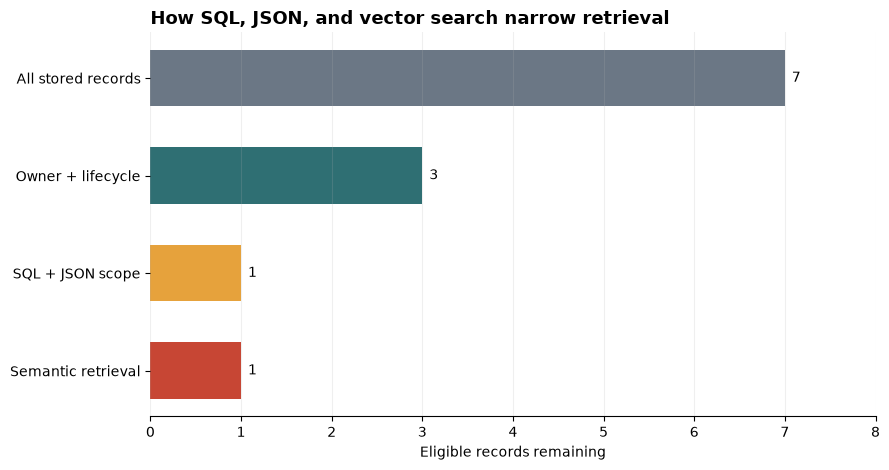

semantic_rank,memory_id,memory_type,source_version,authority,distance,owner_scope,json_scope,lifecycle,decision
1,A371742E_PREF_V3,preference,conversation-2026-11-20-v3,customer,0.599332,PASS,PASS,ACTIVE,ELIGIBLE


Retrieval funnel and decision table: PASS


In [19]:
import matplotlib.pyplot as plt

current_semantic_preferences = scoped_preference_search(OWNER_ID)
assert not current_semantic_preferences.empty, "Current semantic search returned no eligible preference."
assert current_semantic_preferences.iloc[0]["memory_id"] == corrected_preference_id

total_count = query_dataframe(
    f"SELECT COUNT(*) AS row_count FROM {MEMORY_TABLE}"
).iloc[0]["row_count"]
owner_lifecycle_count = query_dataframe(
    f"""
    SELECT COUNT(*) AS row_count
      FROM {MEMORY_TABLE}
     WHERE owner_id = :owner_id
       AND status = 'ACTIVE'
       AND (valid_until IS NULL OR valid_until > SYSTIMESTAMP)
    """,
    {"owner_id": OWNER_ID},
).iloc[0]["row_count"]
json_scope_count = query_dataframe(
    f"""
    SELECT COUNT(*) AS row_count
      FROM {MEMORY_TABLE}
     WHERE owner_id = :owner_id
       AND status = 'ACTIVE'
       AND (valid_until IS NULL OR valid_until > SYSTIMESTAMP)
       AND memory_type = 'preference'
       AND JSON_VALUE(metadata, '$.domain') = :domain
    """,
    {"owner_id": OWNER_ID, "domain": "support"},
).iloc[0]["row_count"]

funnel = pd.DataFrame(
    [
        {"stage": "All stored records", "rule": "No filter", "eligible_records": int(total_count)},
        {"stage": "Owner + lifecycle", "rule": "SQL scope and ACTIVE validity", "eligible_records": int(owner_lifecycle_count)},
        {"stage": "SQL + JSON scope", "rule": "Preference and support domain", "eligible_records": int(json_scope_count)},
        {"stage": "Semantic retrieval", "rule": "Top eligible vector result", "eligible_records": len(current_semantic_preferences)},
    ]
)
display_records(funnel, "Retrieval funnel: each database rule narrows the candidate set")

fig, ax = plt.subplots(figsize=(9, 4.8))
bars = ax.barh(
    funnel["stage"],
    funnel["eligible_records"],
    color=["#6b7785", "#2f6f73", "#e6a23c", "#c74634"],
    height=0.58,
)
ax.invert_yaxis()
ax.set_title("How SQL, JSON, and vector search narrow retrieval", loc="left", fontsize=13, fontweight="bold")
ax.set_xlabel("Eligible records remaining")
ax.grid(axis="x", alpha=0.2)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.bar_label(bars, labels=[str(value) for value in funnel["eligible_records"]], padding=5)
ax.set_xlim(0, max(int(total_count) + 1, 2))
plt.tight_layout()
plt.show()

retrieval_contract = current_semantic_preferences[
    ["memory_id", "memory_type", "source_version", "authority", "distance"]
].copy()
retrieval_contract.insert(0, "semantic_rank", range(1, len(retrieval_contract) + 1))
retrieval_contract["owner_scope"] = "PASS"
retrieval_contract["json_scope"] = "PASS"
retrieval_contract["lifecycle"] = "ACTIVE"
retrieval_contract["decision"] = "ELIGIBLE"
display_records(
    retrieval_contract,
    "Final eligible result after the retrieval funnel",
)
print("Retrieval funnel and decision table: PASS")


## What This Demonstration Shows

- Oracle AI Database can keep structured lifecycle fields, flexible JSON metadata, text evidence, and vector embeddings together in one governed data layer.
- SQL predicates can enforce owner, tenant, lifecycle, and exact-identifier constraints before semantic ranking is used.
- Database-resident `VECTOR_EMBEDDING` keeps stored and query vectors on the same model path.
- Versioning and tombstones make correction and deletion observable instead of leaving stale records to compete with current evidence.

The notebook shows both paths explicitly: the Oracle AI Agent Memory SDK is the application-facing path, while the separate SQL/JSON/vector section makes database primitives visible. They use the same Oracle AI Database connection but separate demonstration stores.


## Optional Cleanup

The demo table is isolated by `RUN_ID`. Leave it in place while inspecting the results. When you are finished, run the following cell to drop only this notebook run's table and close the connection.

In [20]:
CLEANUP_DEMO_OBJECTS = False

if CLEANUP_DEMO_OBJECTS and connection is not None:
    await agent_memory.delete_agent_async(SDK_AGENT_ID, cascade=True)
    await agent_memory.delete_user_async(SDK_USER_ID, cascade=True)
    print("Agent Memory demo records removed: READY")
    with connection.cursor() as cursor:
        cursor.execute(f"DROP TABLE {MEMORY_TABLE} PURGE")
    connection.commit()
    print(f"Removed demo table {MEMORY_TABLE}: READY")
else:
    print("Agent Memory demo records retained for inspection")
    print(f"Cleanup skipped; demo table retained for inspection: {MEMORY_TABLE}")

if connection is not None:
    connection.close()
    print("Oracle connection closed: READY")

Agent Memory demo records retained for inspection
Cleanup skipped; demo table retained for inspection: AI_MEMORY_A371742E
Oracle connection closed: READY


## References

- [Oracle Cloud Free Tier](https://www.oracle.com/cloud/free/)
- [Run Oracle AI Database locally with Docker or Podman](https://docs.oracle.com/en/database/oracle/agent-memory/26.8/guide/run-locally.html)
- [Oracle AI Database Free installation guide](https://docs.oracle.com/en/database/oracle/oracle-database/26/xeinl/installing-oracle-ai-database-free.html)
- [Oracle AI Vector Search overview](https://docs.oracle.com/en/database/oracle/oracle-database/26/vecse/overview-ai-vector-search.html)
- [Oracle AI Vector Search User's Guide](https://docs.oracle.com/en/database/oracle/oracle-database/26/vecse/index.html)
- [`VECTOR_EMBEDDING` SQL function](https://docs.oracle.com/en/database/oracle/oracle-database/26/vecse/vector_embedding.html)
- [Vector distance functions and operators](https://docs.oracle.com/en/database/oracle/oracle-database/26/vecse/vector-distance-functions-and-operators.html)
- [JSON in Oracle AI Database](https://docs.oracle.com/en/database/oracle/oracle-database/26/adjsn/overview-json-oracle-ai-database.html)
- [`JSON_VALUE` SQL function](https://docs.oracle.com/en/database/oracle/oracle-database/26/sqlrf/JSON_VALUE.html)
- [`JSON_EXISTS` SQL/JSON condition](https://docs.oracle.com/en/database/oracle/oracle-database/26/adjsn/sql-json-condition-json_exists.html)
- [Oracle AI Agent Memory metadata filtering](https://docs.oracle.com/en/database/oracle/agent-memory/26.8/guide/int-use-metadata-filtering.html)
- [Oracle AI Agent Memory: get started](https://docs.oracle.com/en/database/oracle/agent-memory/26.8/guide/get-started.html)
